# Chapter 86: Workplace Incentives, Efficiency Wages, Tournaments, and Contracts

This notebook reruns four worked examples from the chapter: dismissal threats and effort, the no-shirking wage floor, back-loaded pay as a bond, and prize spreads that reward both effort and sabotage. Every number is one of the chapter's hypothetical values; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def dismissal_threat(q, premium, months, c):
    """efficiency-wage-discipline-mechanism (chapter 86): R = months x premium; effort if qR >= c.

    Book: R = 3(500) = 1,500, qR = 0.20(1,500) = 300 = c (binds); one month gives 100; q 0.60 with
    R 500 gives 300.
    """
    R = months * premium
    return {"R": R, "qR": q * R, "effort": q * R >= c}


def no_shirking_wage(b, c, r, s, a, q):
    """no-shirking-efficiency-wage (chapter 86): w_NS = b + c + (r + s + a) c / q.

    Book: 36 + 4 + 0.65(4)/0.25 = 50.4; q 0.50 gives 45.2; a 1.00 gives 58.4.
    """
    rent = (r + s + a) * c / q
    return {"rent": rent, "w_NS": b + c + rent}


def bond_constraint(q, claim, saved):
    """deferred-compensation-bonding (chapter 86): effort if saved <= q x claim.

    Book: 0.25(15,000) = 3,750 > 3,000 (effort); q 0.10 gives 1,500 (shirk).
    """
    exp = q * claim
    return {"forfeit": exp, "effort": saved <= exp}


def tournament_returns(spread, slope, cost):
    """tournament-incentives (chapter 86): expected prize return slope x spread, taken if > cost,
    indifferent if equal. Book: 0.10(8,000) = 800 > 600; 0.05 gives 400; 0.05(16,000) = 800;
    sabotage 0.03(8,000) = 240 < 300 and 0.03(16,000) = 480 > 300.
    """
    ret = slope * spread
    diff = ret - cost
    return {"return": ret, "net": diff, "status": "pays" if diff > 1e-9 else ("tie" if abs(diff) <= 1e-9 else "fails")}


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(dismissal_threat=dismissal_threat, no_shirking_wage=no_shirking_wage, bond_constraint=bond_constraint, tournament_returns=tournament_returns)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'efficiency-wage-discipline-mechanism': {'c': 300,
                                          'q': 0.2,
                                          'premium': 500,
                                          'months': 3,
                                          'R': 1500,
                                          'qR': 300,
                                          'R_1': 500,
                                          'qR_1': 100,
                                          'q_high': 0.6,
                                          'qR_high': 300},
 'no-shirking-efficiency-wage': {'b': 36,
                                 'c': 4,
                                 'r': 0.05,
                                 's': 0.1,
                                 'a': 0.5,
                                 'q': 0.25,
                                 'w_NS': 50.4,
                                 'q_high': 0.5,
                                 'w_NS_q': 45.2,
                                 'a_high': 1.0,
                                 'w_NS_a': 58.4,
                                 'job_value': 54},
 'deferred-compensation-bonding': {'pay': (45000, 55000, 80000),
                                   'productivity': 60000,
                                   'total': 180000,
                                   'remaining': 135000,
                                   'outside': 120000,
                                   'claim': 15000,
                                   'saved': 3000,
                                   'q': 0.25,
                                   'forfeit': 3750,
                                   'q_low': 0.1,
                                   'forfeit_low': 1500},
 'tournament-incentives': {'spread': 8000,
                           'cost': 600,
                           'slope': 0.1,
                           'ret': 800,
                           'slope_noisy': 0.05,
                           'ret_noisy': 400,
                           'spread_wide': 16000,
                           'ret_wide': 800,
                           'sab_cost': 300,
                           'sab_slope': 0.03,
                           'harm': 1000,
                           'sab_ret': 240,
                           'sab_ret_wide': 480},
 'constructed': {'efficiency-wage-discipline-mechanism': {'q': [0.4], 'months': [2]},
                 'no-shirking-efficiency-wage': {'a': [0.75]},
                 'deferred-compensation-bonding': {'q': [0.4], 'saved': [4000]},
                 'tournament-incentives': {'spread': [12000]}}}


def _rel(a, b):
    return ">" if a > b + 1e-9 else ("<" if a < b - 1e-9 else "=")


def discipline_picture(q=0.20, months=3):
    b = BV["efficiency-wage-discipline-mechanism"]
    c = b["c"]
    r = labor.dismissal_threat(q, b["premium"], months, c)
    R, qR = r["R"], r["qR"]
    fig, ax = new_figure()
    bar_compare(ax, ["Expected forfeiture qR", "Effort cost c"], [qR, c], colors=["teal", "terracotta"],
                value_labels=[num(qR, 0), num(c, 0)], ylabel="Units per month", xlabel="Lee's comparison")
    ax.set_ylim(0, 1000)
    if qR > c + 1e-9:
        verdict = "the threat disciplines: shirking costs more than it saves"
    elif qR < c - 1e-9:
        verdict = "the threat fails: shirking saves more than it is expected to cost"
    else:
        verdict = "the constraint just binds (a tie) and effort is only weakly supported"
    metrics = {"Rent lost R": num(R, 0), "Expected forfeiture qR": num(qR, 0), "Effort cost c": num(c, 0),
               "Discipline": "Holds" if qR > c + 1e-9 else ("Fails" if qR < c - 1e-9 else "Just binds (tie)")}
    steps = [f"R = {num(months, 0)} x 500 = {num(R, 0)} units",
             f"qR = {num(q)} x {num(R, 0)} = {num(qR, 0)} units",
             f"Compare: {num(qR, 0)} {_rel(qR, c)} 300, so {verdict}"]
    interp = (f"Hypothetical warehouse from the chapter. With {num(months, 0)} expected jobless "
              f"{'month' if months == 1 else 'months'} the rent at "
              f"stake is {num(months, 0)} x 500 = {num(R, 0)} units, and detection at {num(q)} makes the expected "
              f"forfeiture {num(q)} x {num(R, 0)} = {num(qR, 0)} against an effort cost of 300, so {verdict}.")
    alt = f"Two bars: expected forfeiture {num(qR, 0)} units beside the effort cost of 300 units."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def noshirk_picture(q=0.25, a=0.50):
    b = BV["no-shirking-efficiency-wage"]
    r = labor.no_shirking_wage(b["b"], b["c"], b["r"], b["s"], a, q)
    rent, w = r["rent"], r["w_NS"]
    job = b["job_value"]
    fig, ax = new_figure()
    stacked_bar(ax, ["No-shirking floor"], [[36], [4], [rent]], ["Unemployment value b", "Effort cost c",
                "Rent term"], colors=["grey", "gold", "teal"], ylabel="Annual pay (thousands)", total_marker=False)
    hline(ax, job, f"job value {num(job, 0)}", col="terracotta", style="solid", x_frac=0.55)
    label(ax, 0, w, f"w_NS = {num(w, 1)}", dx=0, dy=-5, ha="center", va="top", box=True)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Wage floor")
    ax.legend(loc="upper left", frameon=False, ncol=3)
    sum_rq = 0.05 + 0.10 + a
    feasible = w <= job
    verdict = (f"the floor of {num(w, 1)} is below the job's value of 54 and the contract is feasible" if w < job else
               (f"the floor equals the job's value of 54 (a tie)" if w == job else
                f"the floor of {num(w, 1)} exceeds the job's value of 54 and the simple wage contract fails"))
    metrics = {"Rent term": num(rent, 1), "No-shirking wage w_NS": num(w, 1),
               "Feasible against 54": "Yes" if feasible else "No"}
    steps = [f"r + s + a = 0.05 + 0.10 + {num(a)} = {num(sum_rq)}",
             f"Rent term = {num(sum_rq)} x 4 / {num(q)} = {num(rent, 1)}",
             f"w_NS = 36 + 4 + {num(rent, 1)} = {num(w, 1)}",
             f"Compare with 54: {verdict}"]
    interp = (f"Hypothetical workplace from the chapter (thousands per year). With detection {num(q)} and job "
              f"finding {num(a)}, w_NS = 36 + 4 + {num(sum_rq)} x 4 / {num(q)} = {num(w, 1)}, so {verdict}.")
    alt = (f"One stacked bar: 36 unemployment value, 4 effort cost and a rent term of {num(rent, 1)}, totalling "
           f"{num(w, 1)}, against a job value line at 54.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bond_picture(q=0.25, saved=3000):
    b = BV["deferred-compensation-bonding"]
    pay, prod, claim = b["pay"], b["productivity"], b["claim"]
    r = labor.bond_constraint(q, claim, saved)
    exp = r["forfeit"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    yrs = np.arange(1, 4)
    ax1.bar(yrs, [p / 1000 for p in pay], color=PALETTE["teal"], width=0.55)
    hline(ax1, prod / 1000, "productivity 60", col="terracotta", style="solid", x_frac=0.02)
    for y, p in zip(yrs, pay):
        label(ax1, y, p / 1000, num(p / 1000, 0), dx=0, dy=4, ha="center", box=False)
    ax1.set_xticks(yrs, ["Year 1", "Year 2", "Year 3"])
    ax1.set_ylim(0, 100)
    ax1.set_ylabel("Pay (thousand units)")
    ax1.set_xlabel("Year of the job")
    bar_compare(ax2, ["Expected forfeiture", "Effort saved"], [exp, saved], colors=["navy", "gold"],
                value_labels=[num(exp, 0), num(saved, 0)], ylabel="Units", xlabel="Year two shirking test")
    ax2.set_ylim(0, 7000)
    if exp > saved:
        verdict = "the bond supports effort"
    elif exp < saved:
        verdict = "shirking pays and the bond fails"
    else:
        verdict = "the two tie and Maria is indifferent"
    metrics = {"Claim at stake": num(claim, 0), "Expected forfeiture": num(exp, 0), "Effort cost saved": num(saved, 0),
               "Verdict": "Effort" if exp > saved else ("Shirk" if exp < saved else "Indifferent (tie)")}
    steps = ["Remaining promised pay = 55,000 + 80,000 = 135,000; outside path = 2 x 60,000 = 120,000",
             "Claim at stake = 135,000 - 120,000 = 15,000",
             f"Expected forfeiture = {num(q)} x 15,000 = {num(exp, 0)}",
             f"Compare: {num(exp, 0)} {_rel(exp, saved)} {num(saved, 0)}, so {verdict}"]
    interp = (f"Hypothetical three-year job from the chapter. Back-loaded pay leaves 15,000 units at stake after "
              f"year one; with detection {num(q)} the expected forfeiture is {num(q)} x 15,000 = {num(exp, 0)} against "
              f"{num(saved, 0)} of effort saved, so {verdict}.")
    alt = (f"Left: pay of 45, 55 and 80 thousand against flat productivity of 60. Right: expected forfeiture "
           f"{num(exp, 0)} beside effort saved {num(saved, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tournament_picture(spread=8000, slope=0.10):
    b = BV["tournament-incentives"]
    prod = labor.tournament_returns(spread, slope, b["cost"])
    sab = labor.tournament_returns(spread, b["sab_slope"], b["sab_cost"])
    fig, ax = new_figure()
    cols = {"pays": "teal", "tie": "gold", "fails": "grey"}
    bar_compare(ax, ["Productive return", "Productive cost", "Sabotage return", "Sabotage cost"],
                [prod["return"], 600, sab["return"], 300],
                colors=[cols[prod["status"]], "light", cols[sab["status"]], "light"],
                value_labels=[num(prod["return"], 0), "600", num(sab["return"], 0), "300"],
                ylabel="Units", xlabel="Action")
    ax.set_ylim(0, 1700)
    word = {"pays": "taken", "tie": "indifferent (tie)", "fails": "not taken"}
    def _so(st):
        return "the manager is indifferent (a tie)" if st == "tie" else f"it is {word[st]}"
    metrics = {"Productive return": num(prod["return"], 0), "Productive action": word[prod["status"]].capitalize(),
               "Sabotage return": num(sab["return"], 0), "Sabotage": word[sab["status"]].capitalize()}
    steps = [f"Productive: {num(slope)} x {num(spread, 0)} = {num(prod['return'], 0)} "
             f"{_rel(prod['return'], 600)} 600, {word[prod['status']]}",
             f"Sabotage: 0.03 x {num(spread, 0)} = {num(sab['return'], 0)} {_rel(sab['return'], 300)} 300, "
             f"{word[sab['status']]}"]
    interp = (f"Hypothetical managers from the chapter with a prize spread of {num(spread, 0)}. The productive action "
              f"returns {num(slope)} x {num(spread, 0)} = {num(prod['return'], 0)} against a cost of 600, so "
              f"{_so(prod['status'])}; sabotage returns 0.03 x {num(spread, 0)} = {num(sab['return'], 0)} against 300, "
              f"so {_so(sab['status'])}. Each act of sabotage also destroys 1,000 units of customer value.")
    alt = (f"Four bars: productive return {num(prod['return'], 0)} against cost 600 and sabotage return "
           f"{num(sab['return'], 0)} against cost 300.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Efficiency-wage discipline: monitoring, joblessness, and effort

Hypothetical warehouse: effort costs 300, the premium is 500 a month and detection is 0.20.

$$qR\geq c, \qquad R=3(500)=1{,}500, \qquad qR=0.20(1{,}500)=300$$

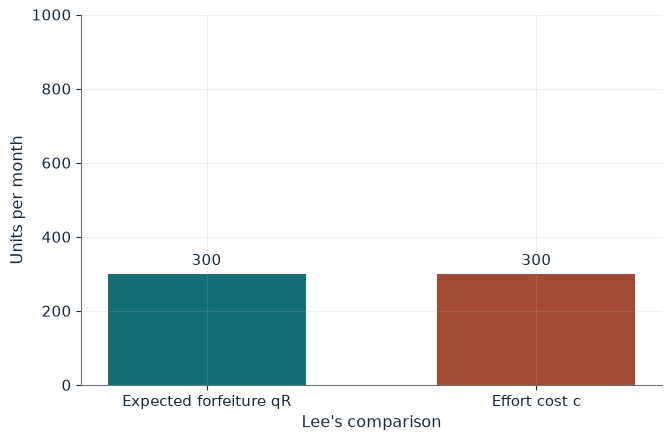

Rent lost R             1,500
Expected forfeiture qR  300
Effort cost c           300
Discipline              Just binds (tie)

Worked steps:
  1. R = 3 x 500 = 1,500 units
  2. qR = 0.20 x 1,500 = 300 units
  3. Compare: 300 = 300, so the constraint just binds (a tie) and effort is only weakly supported

Hypothetical warehouse from the chapter. With 3 expected jobless months the rent at stake is 3 x 500 = 1,500 units, and detection at 0.20 makes the expected forfeiture 0.20 x 1,500 = 300 against an effort cost of 300, so the constraint just binds (a tie) and effort is only weakly supported.


In [2]:
show(discipline_picture(q=0.20, months=3))

Change one input, `months`, and hold the others at the book's values:

In [3]:
sweep(discipline_picture, 'months', [1, 2, 3], {'q': 0.2}, ['Expected forfeiture qR', 'Discipline'])

months | Expected forfeiture qR | Discipline
1 | 100 | Fails
2 | 200 | Fails
3 | 300 | Just binds (tie)


With three jobless months the constraint just binds; one month leaves an expected loss of only 100.

## 2. No-shirking wage: the floor

Hypothetical values in thousands: b = 36, c = 4, r = 0.05, s = 0.10.

$$w\geq b+c+\frac{(r+s+a)c}{q}, \qquad w_{NS}=36+4+\frac{(0.05+0.10+0.50)4}{0.25}=50.4$$

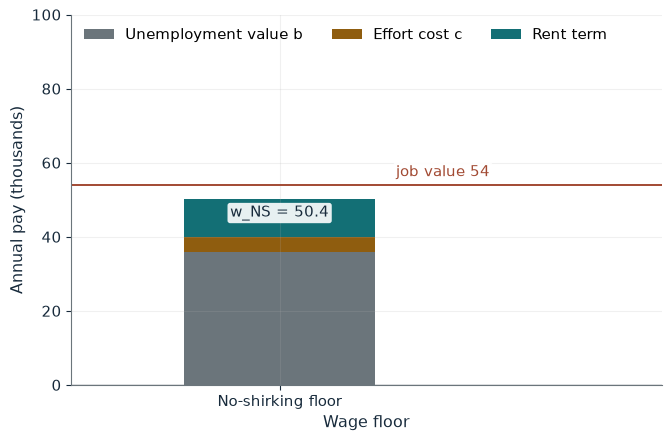

Rent term              10.4
No-shirking wage w_NS  50.4
Feasible against 54    Yes

Worked steps:
  1. r + s + a = 0.05 + 0.10 + 0.50 = 0.65
  2. Rent term = 0.65 x 4 / 0.25 = 10.4
  3. w_NS = 36 + 4 + 10.4 = 50.4
  4. Compare with 54: the floor of 50.4 is below the job's value of 54 and the contract is feasible

Hypothetical workplace from the chapter (thousands per year). With detection 0.25 and job finding 0.50, w_NS = 36 + 4 + 0.65 x 4 / 0.25 = 50.4, so the floor of 50.4 is below the job's value of 54 and the contract is feasible.


In [4]:
show(noshirk_picture(q=0.25, a=0.50))

Change one input, `a`, and hold the others at the book's values:

In [5]:
sweep(noshirk_picture, 'a', [0.5, 0.75, 1.0], {'q': 0.25}, ['No-shirking wage w_NS', 'Feasible against 54'])

a | No-shirking wage w_NS | Feasible against 54
0.5 | 50.4 | Yes
0.75 | 54.4 | No
1.0 | 58.4 | No


Faster job finding raises the floor; at a = 1.00 it reaches 58.4, above the job's value of 54.

## 3. Deferred-compensation bonding: back-loaded pay

Hypothetical job: pay 45,000, 55,000 and 80,000 against productivity 60,000 a year.

$$c\leq q\left(V_{t+1}-V_{t+1}^{out}\right), \qquad 0.25(15{,}000)=3{,}750$$

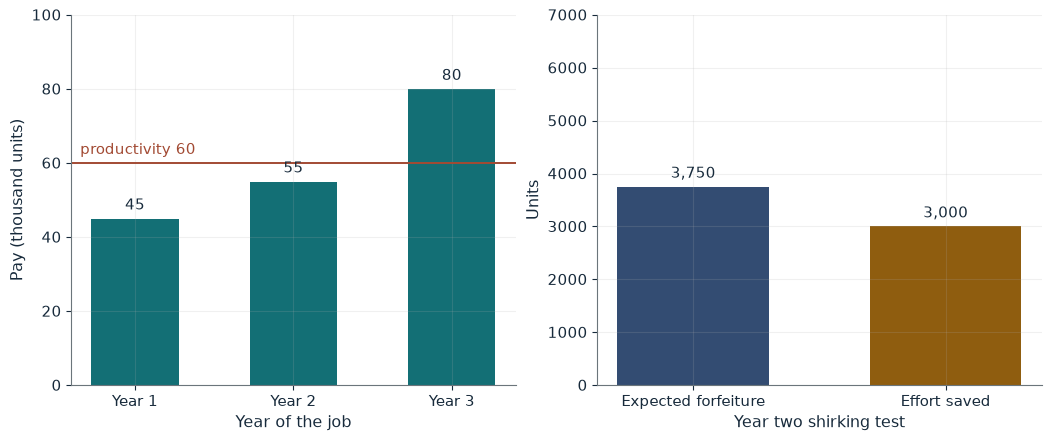

Claim at stake       15,000
Expected forfeiture  3,750
Effort cost saved    3,000
Verdict              Effort

Worked steps:
  1. Remaining promised pay = 55,000 + 80,000 = 135,000; outside path = 2 x 60,000 = 120,000
  2. Claim at stake = 135,000 - 120,000 = 15,000
  3. Expected forfeiture = 0.25 x 15,000 = 3,750
  4. Compare: 3,750 > 3,000, so the bond supports effort

Hypothetical three-year job from the chapter. Back-loaded pay leaves 15,000 units at stake after year one; with detection 0.25 the expected forfeiture is 0.25 x 15,000 = 3,750 against 3,000 of effort saved, so the bond supports effort.


In [6]:
show(bond_picture(q=0.25, saved=3000))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(bond_picture, 'q', [0.1, 0.25, 0.4], {'saved': 3000}, ['Expected forfeiture', 'Verdict'])

q | Expected forfeiture | Verdict
0.1 | 1,500 | Shirk
0.25 | 3,750 | Effort
0.4 | 6,000 | Effort


The 15,000 claim at stake deters shirking at q = 0.25 (3,750 > 3,000) but not at q = 0.10 (1,500).

## 4. Tournament incentives: effort and sabotage

Hypothetical spread 8,000; productive action costs 600, sabotage 300 with slope 0.03.

$$0.10(8{,}000)=800, \qquad 0.03(16{,}000)=480$$

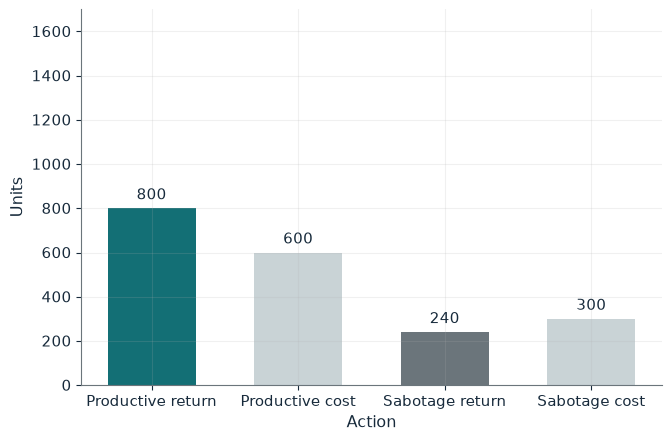

Productive return  800
Productive action  Taken
Sabotage return    240
Sabotage           Not taken

Worked steps:
  1. Productive: 0.10 x 8,000 = 800 > 600, taken
  2. Sabotage: 0.03 x 8,000 = 240 < 300, not taken

Hypothetical managers from the chapter with a prize spread of 8,000. The productive action returns 0.10 x 8,000 = 800 against a cost of 600, so it is taken; sabotage returns 0.03 x 8,000 = 240 against 300, so it is not taken. Each act of sabotage also destroys 1,000 units of customer value.


In [8]:
show(tournament_picture(spread=8000, slope=0.10))

Change one input, `spread`, and hold the others at the book's values:

In [9]:
sweep(tournament_picture, 'spread', [8000, 12000, 16000], {'slope': 0.05}, ['Productive action', 'Sabotage'])

spread | Productive action | Sabotage
8000 | Not taken | Not taken
12000 | Indifferent (tie) | Taken
16000 | Taken | Taken


Under noise (slope 0.05) widening the spread to 16,000 restores productive effort but also makes sabotage pay.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

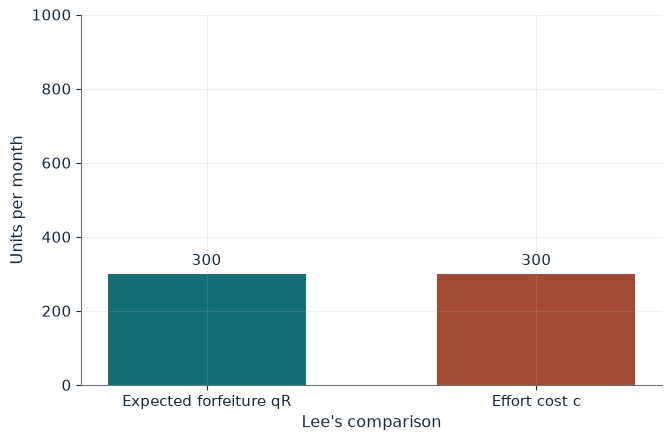

Rent lost R             1,500
Expected forfeiture qR  300
Effort cost c           300
Discipline              Just binds (tie)

Worked steps:
  1. R = 3 x 500 = 1,500 units
  2. qR = 0.20 x 1,500 = 300 units
  3. Compare: 300 = 300, so the constraint just binds (a tie) and effort is only weakly supported

Hypothetical warehouse from the chapter. With 3 expected jobless months the rent at stake is 3 x 500 = 1,500 units, and detection at 0.20 makes the expected forfeiture 0.20 x 1,500 = 300 against an effort cost of 300, so the constraint just binds (a tie) and effort is only weakly supported.


In [10]:
show(discipline_picture(q=0.20, months=3))

## Practice

**1.** With q = 0.40 and two jobless months, does discipline hold?

<details><summary>Answer</summary>

R = 1,000 and qR = 400 > 300, so yes.

</details>

**2.** With q = 0.50 and a = 0.75, what is w_NS?

<details><summary>Answer</summary>

36 + 4 + 0.90 x 4 / 0.50 = 47.2.

</details>

**3.** At spread 12,000 and slope 0.05, which actions pay?

<details><summary>Answer</summary>

Productive 600 equals its cost (indifferent); sabotage 360 > 300 pays.

</details>